# Wine Quality: окремі датасети vs спільний vs без `wine_type`

**Питання:** як наявність / відсутність поділу даних за типом вина (червоне/біле) впливає на якість Random Forest (регресія оцінки `quality`), і які хімічні показники найважливіші за permutation importance?

**Сценарії:**
1. `red` — модель тільки на червоному вині
2. `white` — модель тільки на білому вині
3. `combined + wine_type` — спільна модель, ознака типу вина є
4. `combined, no wine_type` — спільна модель без ознаки типу вина

**Схема:** видалення дублікатів → baseline (константа = середнє) → 5-fold CV (однакові фолди для всіх сценаріїв) → hold-out оцінка через `evaluate_classification_metrics` → permutation importance.

> Дублікати видаляються **до** розбиття на train/test, інакше однакові рядки потрапляють і в train, і в test (витік даних).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, mean_squared_error, mean_absolute_error, r2_score)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)

numpy 2.5.3 | pandas 3.0.5 | sklearn 1.9.1


## Допоміжна функція оцінки (надана)

In [2]:
def evaluate_classification_metrics(model, X_valid, y_valid, title="Classification Report"):
    """
    Універсальна функція для оцінки моделей (включно з регресорами)
    за метриками класифікації.
    """
    # 1. Робимо прогнози
    predictions = model.predict(X_valid)

    # 2. Якщо модель повертає дробові числа (регресія), округлюємо їх
    predictions_rounded = np.round(predictions)

    # 3. Розрахунок стандартних метрик
    # zero_division=0 запобігає появі попереджень, якщо модель ніколи не прогнозувала певний клас
    acc = accuracy_score(y_valid, predictions_rounded)
    prec = precision_score(y_valid, predictions_rounded, average='macro', zero_division=0)
    rec = recall_score(y_valid, predictions_rounded, average='macro', zero_division=0)
    f1 = f1_score(y_valid, predictions_rounded, average='macro', zero_division=0)

    print(f"--- {title} ---")
    print(f"Accuracy:  {acc:.4f} (Відсоток ідеальних влучань)")
    print(f"Precision: {prec:.4f} (Macro)")
    print(f"Recall:    {rec:.4f} (Macro)")
    print(f"F1-Score:  {f1:.4f} (Macro)\n")

    # 4. Класифікація якості похибки (наша власна метрика)
    exact_matches = np.sum(predictions_rounded == y_valid)
    off_by_one = np.sum(np.abs(predictions_rounded - y_valid) == 1)
    total = len(y_valid)

    print("--- Розподіл похибок ---")
    print(f"Точне влучання (Exact match): {exact_matches/total*100:.2f}%")
    print(f"Похибка на 1 бал (Off by 1):  {off_by_one/total*100:.2f}%")
    print(f"Груба похибка (>1 бала):      {(total - exact_matches - off_by_one)/total*100:.2f}%\n")

    # 5. Красива візуалізація матриці плутанини
    cm = confusion_matrix(y_valid, predictions_rounded)

    # Отримуємо унікальні класи (оцінки), які реально присутні у валідаційній вибірці
    classes = np.unique(np.concatenate([y_valid, predictions_rounded]))

    plt.figure(figsize=(8, 6))
    # annot=True показує цифри, cmap='Blues' задає синю кольорову гаму
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes)

    plt.title(f'Confusion Matrix: {title}')
    plt.ylabel('Справжня оцінка (Actual)')
    plt.xlabel('Прогноз моделі (Predicted)')
    plt.tight_layout()
    plt.show()

## 1. Завантаження даних і видалення дублікатів

In [3]:
# Файли з UCI розділені символом ';'. Шляхи за потреби змініть.
RED_PATH   = "dataset/winequality-red.csv"
WHITE_PATH = "dataset/winequality-white.csv"

red_raw   = pd.read_csv(RED_PATH,   sep=";")
white_raw = pd.read_csv(WHITE_PATH, sep=";")

red_raw["wine_type"]   = 0   # 0 = red
white_raw["wine_type"] = 1   # 1 = white

print("Пропуски:", int(red_raw.isna().sum().sum()), "(red),", int(white_raw.isna().sum().sum()), "(white)")

# Дублікати видаляємо в кожному датасеті окремо (wine_type у рядку однаковий, тож це рівнозначно
# видаленню по всіх колонках у об'єднаному). Рядок, що збігся між red і white, лишається в обох.
red   = red_raw.drop_duplicates().reset_index(drop=True)
white = white_raw.drop_duplicates().reset_index(drop=True)

summary = pd.DataFrame({
    "до":    [len(red_raw), len(white_raw)],
    "після": [len(red), len(white)],
}, index=["red", "white"])
summary["видалено"] = summary["до"] - summary["після"]
summary["% дублікатів"] = (summary["видалено"] / summary["до"] * 100).round(1)
display(summary)

df = pd.concat([red, white], ignore_index=True)
print("Спільний датасет:", df.shape)

Пропуски: 0 (red), 0 (white)


,до,після,видалено,% дублікатів
red,1599,1359,240,15.0
white,4898,3961,937,19.1


Спільний датасет: (5320, 13)


wine_type,red,white
quality,,
3,10,20
4,53,153
5,577,1175
6,535,1788
7,167,689
8,17,131
9,0,5


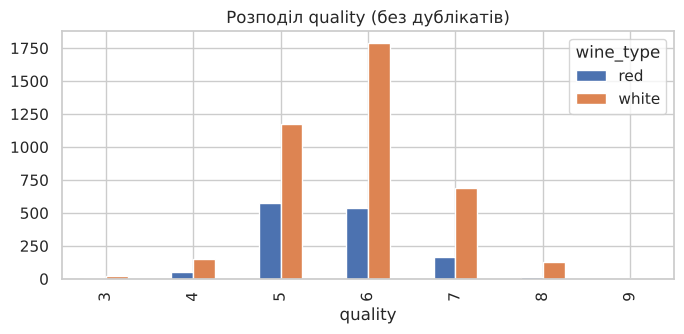

In [4]:
# Розподіл цільової змінної після очищення
dist = pd.crosstab(df["quality"], df["wine_type"].map({0: "red", 1: "white"}))
display(dist)
dist.plot(kind="bar", figsize=(7, 3.5), title="Розподіл quality (без дублікатів)")
plt.tight_layout(); plt.show()

## 2. Налаштування експерименту

* Модель: `RandomForestRegressor(n_estimators=300, random_state=42)`; базові гіперпараметри, налаштування не робимо — ціль порівняти сценарії.
* Baseline: `DummyRegressor(mean)`.
* Усі кроки в `Pipeline` (тут лише модель, бо RF не потребує масштабування — тож витоку через препроцесинг немає).
* **Однакові фолди** для всіх сценаріїв: `StratifiedKFold` по комбінації `wine_type + quality`. Тому на кожному рядку можна порівняти прогнози кожного сценарію.
* Метрики: RMSE, MAE, R² (регресійні) + accuracy після округлення та частка «±1 бал» (як у наданій функції).

**Чесність порівняння:** метрики на `red`-тесті та на `white`-тесті — це різні вибірки, тому напряму порівнювати «red-модель» з «combined-моделлю» на всьому тесті некоректно. Тому для спільних моделей рахуємо метрики окремо на red- та white-підмножині.

In [5]:
FEATURES = [c for c in df.columns if c not in ("quality", "wine_type")]
FEATURES_WITH_TYPE = FEATURES + ["wine_type"]

def make_rf():
    return Pipeline([("rf", RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED))])

def make_dummy():
    return Pipeline([("dummy", DummyRegressor(strategy="mean"))])

def reg_metrics(y_true, y_pred):
    r = np.round(y_pred)
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "Accuracy": accuracy_score(y_true, r),
        "Within±1": np.mean(np.abs(r - y_true) <= 1),
    }

## 3. Крос-валідація (5-fold) — out-of-fold прогнози для кожного сценарію

In [6]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
strat = df["wine_type"].astype(str) + "_" + df["quality"].astype(str)
folds = list(skf.split(df, strat))

y = df["quality"].to_numpy()
is_red, is_white = (df["wine_type"] == 0).to_numpy(), (df["wine_type"] == 1).to_numpy()

scenarios = {
    "baseline (mean)":          dict(feats=FEATURES,           per_type=False, factory=make_dummy),
    "red only":                 dict(feats=FEATURES,           per_type=True,  factory=make_rf, only=0),
    "white only":               dict(feats=FEATURES,           per_type=True,  factory=make_rf, only=1),
    "combined + wine_type":     dict(feats=FEATURES_WITH_TYPE, per_type=False, factory=make_rf),
    "combined, no wine_type":   dict(feats=FEATURES,           per_type=False, factory=make_rf),
}

oof = {}   # out-of-fold прогнози: name -> масив довжини len(df) (NaN там, де сценарій не застосовний)
for name, cfg in scenarios.items():
    pred = np.full(len(df), np.nan)
    for tr, te in folds:
        if "only" in cfg:                       # окрема модель: тренуємо та тестуємо лише на своєму типі
            tr = tr[df["wine_type"].to_numpy()[tr] == cfg["only"]]
            te = te[df["wine_type"].to_numpy()[te] == cfg["only"]]
        m = cfg["factory"]().fit(df.iloc[tr][cfg["feats"]], y[tr])
        pred[te] = m.predict(df.iloc[te][cfg["feats"]])
    oof[name] = pred
print("Готово")

Готово


In [7]:
# Об'єднуємо 'red only' + 'white only' у «роздільний підхід» (кожне вино оцінює модель свого типу)
oof["separate (red+white models)"] = np.where(is_red, oof["red only"], oof["white only"])

def table(mask, names):
    rows = {n: reg_metrics(y[mask], oof[n][mask]) for n in names}
    return pd.DataFrame(rows).T.round(4)

names_cmp = ["baseline (mean)", "separate (red+white models)", "combined + wine_type", "combined, no wine_type"]

print("=== Усі вина (red + white) ===")
res_all = table(np.ones(len(df), bool), names_cmp); display(res_all)
print("=== Тільки червоні ===")
res_red = table(is_red, names_cmp); display(res_red)
print("=== Тільки білі ===")
res_white = table(is_white, names_cmp); display(res_white)

=== Усі вина (red + white) ===


,RMSE,MAE,R2,Accuracy,Within±1
baseline (mean),0.8797,0.6947,-0.0000,0.4367,0.9269
separate (red+white models),0.6867,0.5286,0.3907,0.5671,0.9620
combined + wine_type,0.6863,0.5273,0.3913,0.5767,0.9630
"combined, no wine_type",0.6861,0.5273,0.3916,0.5763,0.9637


=== Тільки червоні ===


,RMSE,MAE,R2,Accuracy,Within±1
baseline (mean),0.8411,0.6844,-0.0439,0.3937,0.9411
separate (red+white models),0.6554,0.5026,0.3662,0.5872,0.9647
combined + wine_type,0.6487,0.4997,0.3791,0.5982,0.9698
"combined, no wine_type",0.6477,0.4995,0.3810,0.6012,0.9720


=== Тільки білі ===


,RMSE,MAE,R2,Accuracy,Within±1
baseline (mean),0.8925,0.6982,-0.0044,0.4514,0.9220
separate (red+white models),0.6971,0.5375,0.3873,0.5602,0.9611
combined + wine_type,0.6988,0.5368,0.3843,0.5693,0.9606
"combined, no wine_type",0.6988,0.5369,0.3842,0.5678,0.9609


In [8]:
# Те саме, але «окрема модель на своєму датасеті» в тому вигляді, як її зазвичай порівнюють (метрики на власному тесті)
own = pd.DataFrame({
    "red model → red":     reg_metrics(y[is_red],   oof["red only"][is_red]),
    "white model → white": reg_metrics(y[is_white], oof["white only"][is_white]),
}).T.round(4)
display(own)

,RMSE,MAE,R2,Accuracy,Within±1
red model → red,0.6554,0.5026,0.3662,0.5872,0.9647
white model → white,0.6971,0.5375,0.3873,0.5602,0.9611


### Стабільність по фолдах
Одне число RMSE може бути випадковістю; дивимось розкид по фолдах (±std) для RMSE окремо на red та white.

In [9]:
rows = []
for name in ["separate (red+white models)", "combined + wine_type", "combined, no wine_type", "baseline (mean)"]:
    for tname, mask in [("red", is_red), ("white", is_white)]:
        vals = []
        for tr, te in folds:
            te_m = te[mask[te]]
            vals.append(np.sqrt(mean_squared_error(y[te_m], oof[name][te_m])))
        rows.append((name, tname, np.mean(vals), np.std(vals)))
fold_df = pd.DataFrame(rows, columns=["scenario", "subset", "RMSE mean", "RMSE std"]).round(4)
display(fold_df.pivot(index="scenario", columns="subset", values=["RMSE mean", "RMSE std"]))

RMSE mean         RMSE std        
subset                            red   white      red   white
scenario                                                      
baseline (mean)                0.8411  0.8925   0.0025  0.0009
combined + wine_type           0.6475  0.6988   0.0391  0.0052
combined, no wine_type         0.6465  0.6988   0.0394  0.0050
separate (red+white models)    0.6545  0.6971   0.0340  0.0048

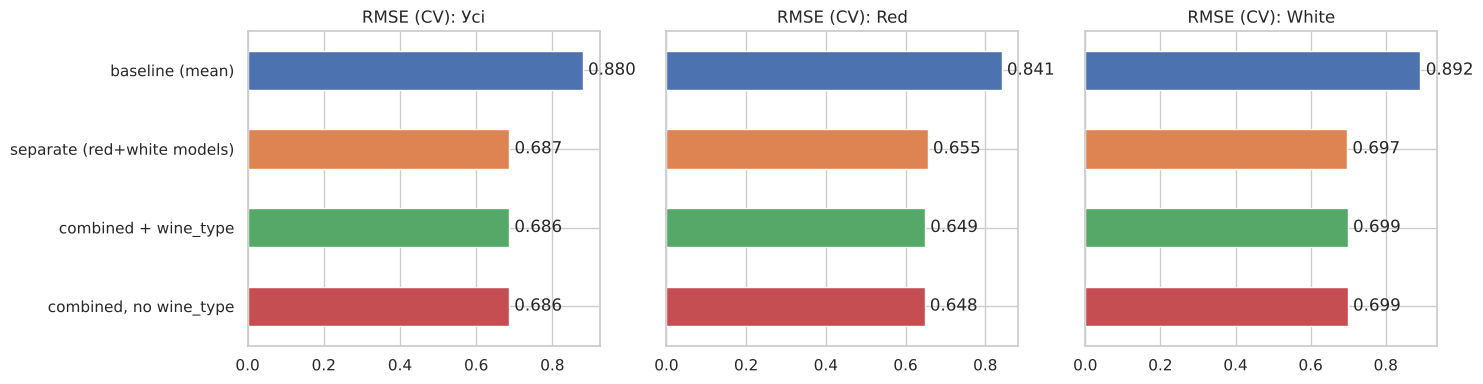

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (title, tbl) in zip(axes, [("Усі", res_all), ("Red", res_red), ("White", res_white)]):
    tbl["RMSE"].plot(kind="barh", ax=ax, color=sns.color_palette("deep")[:len(tbl)])
    ax.set_title(f"RMSE (CV): {title}"); ax.invert_yaxis()
    for i, v in enumerate(tbl["RMSE"]): ax.text(v, i, f" {v:.3f}", va="center")
plt.tight_layout(); plt.show()

## 4. Hold-out (80/20) з наданою функцією `evaluate_classification_metrics`

Один спільний стратифікований поділ; **той самий тест** для всіх сценаріїв.
Окремі моделі тренуються на train-частині свого типу та тестуються на test-частині свого типу.

In [11]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=SEED,
                                     stratify=df["wine_type"].astype(str) + "_" + df["quality"].astype(str))
tr_red,  te_red  = train_df[train_df.wine_type == 0], test_df[test_df.wine_type == 0]
tr_white, te_white = train_df[train_df.wine_type == 1], test_df[test_df.wine_type == 1]
print(len(train_df), "train /", len(test_df), "test")

rf_red   = make_rf().fit(tr_red[FEATURES],   tr_red["quality"])
rf_white = make_rf().fit(tr_white[FEATURES], tr_white["quality"])
rf_comb  = make_rf().fit(train_df[FEATURES_WITH_TYPE], train_df["quality"])
rf_nowt  = make_rf().fit(train_df[FEATURES],           train_df["quality"])

4256 train / 1064 test


--- RED model on RED test ---
Accuracy:  0.6273 (Відсоток ідеальних влучань)
Precision: 0.4685 (Macro)
Recall:    0.3148 (Macro)
F1-Score:  0.3259 (Macro)

--- Розподіл похибок ---
Точне влучання (Exact match): 62.73%
Похибка на 1 бал (Off by 1):  34.69%
Груба похибка (>1 бала):      2.58%



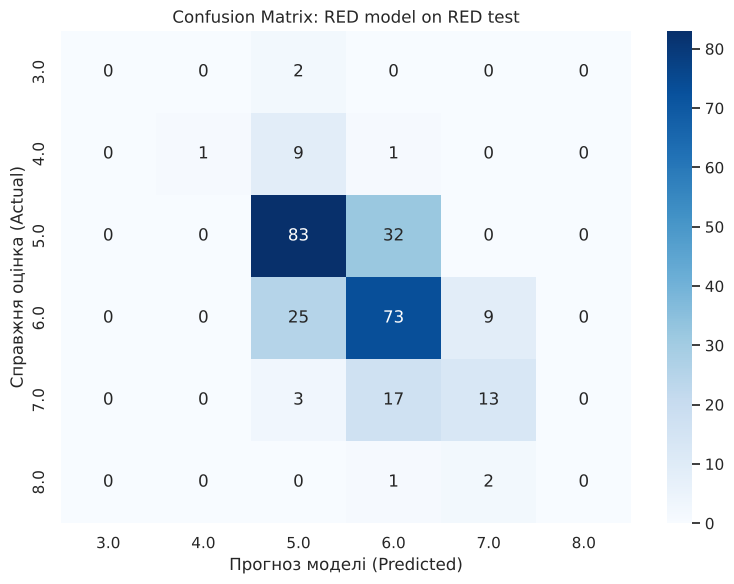

In [12]:
evaluate_classification_metrics(rf_red, te_red[FEATURES], te_red["quality"], title="RED model on RED test")

--- WHITE model on WHITE test ---
Accuracy:  0.5561 (Відсоток ідеальних влучань)
Precision: 0.2338 (Macro)
Recall:    0.2415 (Macro)
F1-Score:  0.2364 (Macro)

--- Розподіл похибок ---
Точне влучання (Exact match): 55.61%
Похибка на 1 бал (Off by 1):  40.23%
Груба похибка (>1 бала):      4.16%



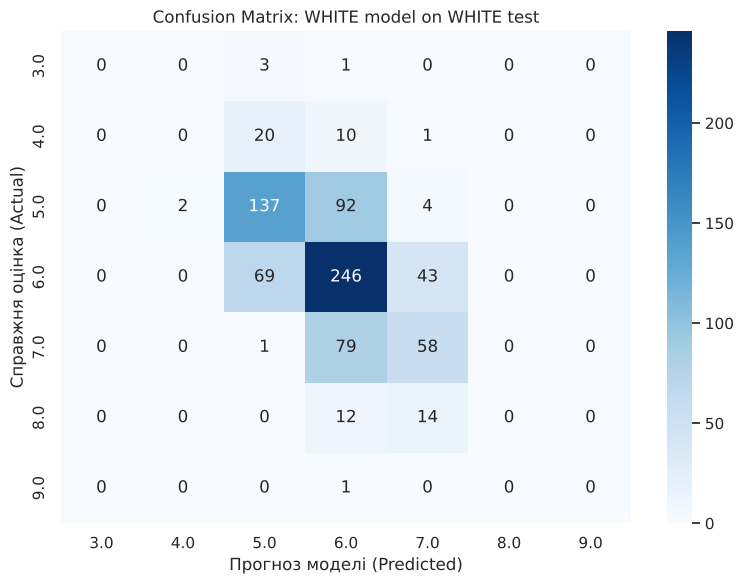

In [13]:
evaluate_classification_metrics(rf_white, te_white[FEATURES], te_white["quality"], title="WHITE model on WHITE test")

--- COMBINED + wine_type (all test) ---
Accuracy:  0.5695 (Відсоток ідеальних влучань)
Precision: 0.2376 (Macro)
Recall:    0.2438 (Macro)
F1-Score:  0.2391 (Macro)

--- Розподіл похибок ---
Точне влучання (Exact match): 56.95%
Похибка на 1 бал (Off by 1):  39.10%
Груба похибка (>1 бала):      3.95%



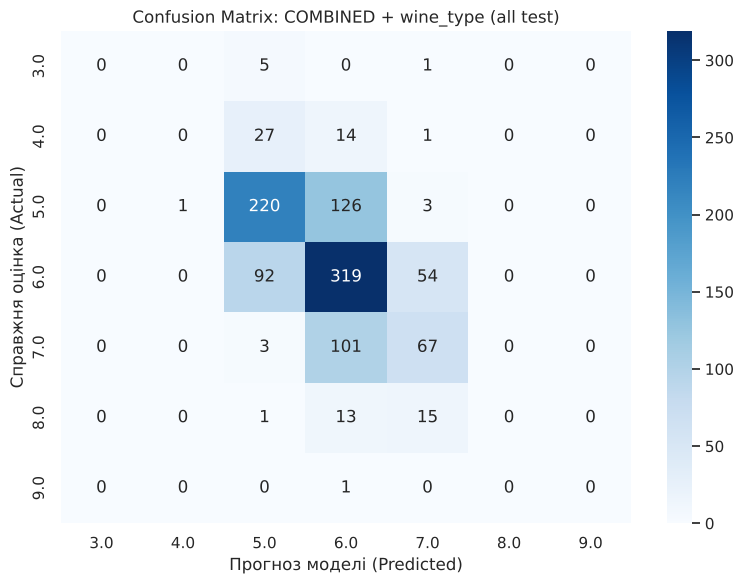

In [14]:
evaluate_classification_metrics(rf_comb, test_df[FEATURES_WITH_TYPE], test_df["quality"], title="COMBINED + wine_type (all test)")

--- COMBINED, no wine_type (all test) ---
Accuracy:  0.5677 (Відсоток ідеальних влучань)
Precision: 0.2374 (Macro)
Recall:    0.2435 (Macro)
F1-Score:  0.2389 (Macro)

--- Розподіл похибок ---
Точне влучання (Exact match): 56.77%
Похибка на 1 бал (Off by 1):  39.47%
Груба похибка (>1 бала):      3.76%



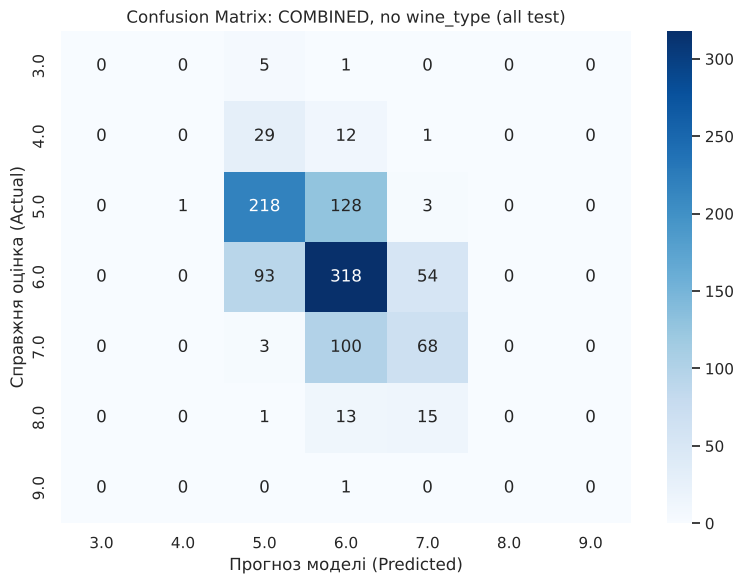

In [15]:
evaluate_classification_metrics(rf_nowt, test_df[FEATURES], test_df["quality"], title="COMBINED, no wine_type (all test)")

In [16]:
# Підсумок hold-out по підмножинах (однакові тестові рядки для всіх)
def holdout_row(model_fn, sub, feats_fn):
    return reg_metrics(sub["quality"].to_numpy(), model_fn(sub[feats_fn]))

hold = pd.DataFrame({
    "separate → red":        holdout_row(rf_red.predict,  te_red,   FEATURES),
    "combined+type → red":   holdout_row(rf_comb.predict, te_red,   FEATURES_WITH_TYPE),
    "combined no type → red":holdout_row(rf_nowt.predict, te_red,   FEATURES),
    "separate → white":        holdout_row(rf_white.predict, te_white, FEATURES),
    "combined+type → white":   holdout_row(rf_comb.predict,  te_white, FEATURES_WITH_TYPE),
    "combined no type → white":holdout_row(rf_nowt.predict,  te_white, FEATURES),
}).T.round(4)
display(hold)

,RMSE,MAE,R2,Accuracy,Within±1
separate → red,0.6250,0.4797,0.4186,0.6273,0.9742
combined+type → red,0.6366,0.4861,0.3969,0.6236,0.9742
combined no type → red,0.6375,0.4852,0.3952,0.6125,0.9742
separate → white,0.7217,0.5545,0.3433,0.5561,0.9584
combined+type → white,0.7227,0.5544,0.3416,0.5511,0.9559
combined no type → white,0.7223,0.5536,0.3423,0.5523,0.9584


## 5. Наскільки погіршується модель без `wine_type`
Різниця спільної моделі без типу відносно спільної з типом (CV, out-of-fold). Позитивна ΔRMSE = гірше.

In [17]:
d = pd.DataFrame({
    "RMSE with type":    [reg_metrics(y[m], oof["combined + wine_type"][m])["RMSE"] for m in (np.ones(len(df), bool), is_red, is_white)],
    "RMSE without type": [reg_metrics(y[m], oof["combined, no wine_type"][m])["RMSE"] for m in (np.ones(len(df), bool), is_red, is_white)],
}, index=["all", "red", "white"])
d["ΔRMSE"] = d["RMSE without type"] - d["RMSE with type"]
d["Δ%"] = d["ΔRMSE"] / d["RMSE with type"] * 100
display(d.round(4))

,RMSE with type,RMSE without type,ΔRMSE,Δ%
all,0.6863,0.6861,-0.0002,-0.0286
red,0.6487,0.6477,-0.0010,-0.1478
white,0.6988,0.6988,0.0000,0.0066


## 6. Permutation importance (на hold-out тесті)
Рахуємо на тестовій частині (не на train), `n_repeats=20`. Показуємо важливість ознак для спільної моделі з `wine_type`, для окремих моделей — і для моделі без типу.

,red model,white model,combined + type,combined no type
alcohol,0.1363,0.1738,0.1690,0.1703
volatile acidity,0.0473,0.0523,0.0632,0.0619
free sulfur dioxide,0.0069,0.0510,0.0454,0.0453
sulphates,0.0782,0.0023,0.0246,0.0254
total sulfur dioxide,0.0180,0.0052,0.0153,0.0158
pH,0.0071,0.0180,0.0127,0.0130
chlorides,0.0024,0.0074,0.0091,0.0093
residual sugar,0.0047,0.0100,0.0073,0.0074
citric acid,0.0044,0.0052,0.0068,0.0064
fixed acidity,0.0008,0.0034,0.0062,0.0058


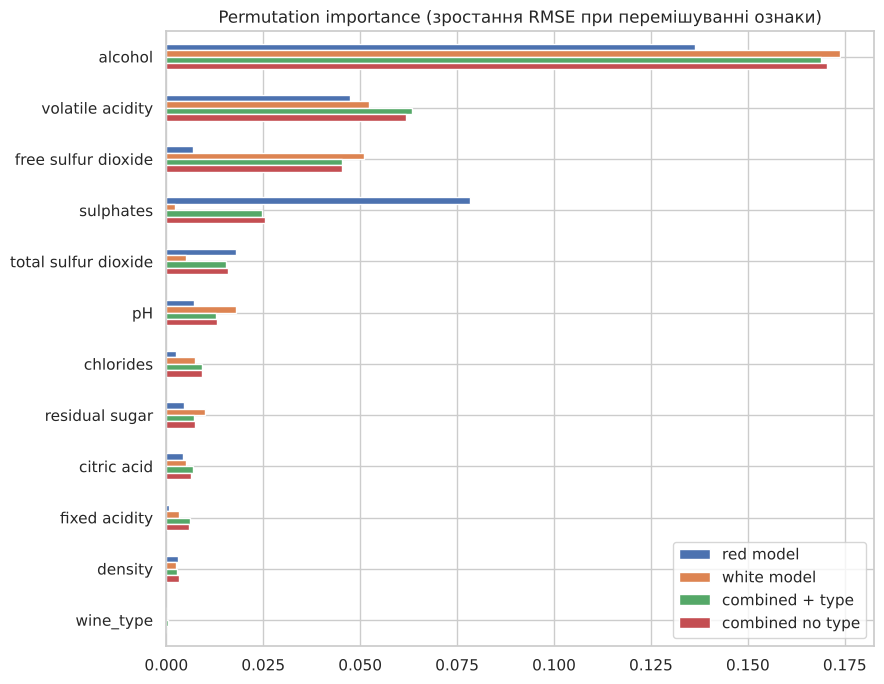

In [18]:
def perm_imp(model, X, y_):
    r = permutation_importance(model, X, y_, n_repeats=20, random_state=SEED,
                               scoring="neg_root_mean_squared_error", n_jobs=-1)
    return pd.Series(r.importances_mean, index=X.columns)

pi = pd.DataFrame({
    "red model":        perm_imp(rf_red,   te_red[FEATURES],   te_red["quality"]),
    "white model":      perm_imp(rf_white, te_white[FEATURES], te_white["quality"]),
    "combined + type":  perm_imp(rf_comb,  test_df[FEATURES_WITH_TYPE], test_df["quality"]),
    "combined no type": perm_imp(rf_nowt,  test_df[FEATURES],           test_df["quality"]),
})
pi = pi.sort_values("combined + type", ascending=False)
display(pi.round(4))

ax = pi.plot(kind="barh", figsize=(9, 7), title="Permutation importance (зростання RMSE при перемішуванні ознаки)")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

## 7. Аналіз помилок: де модель помиляється

,mean,count
quality,,
3,2.391,30
4,1.263,206
5,0.455,1752
6,0.376,2323
7,0.669,856
8,1.477,148
9,2.319,5


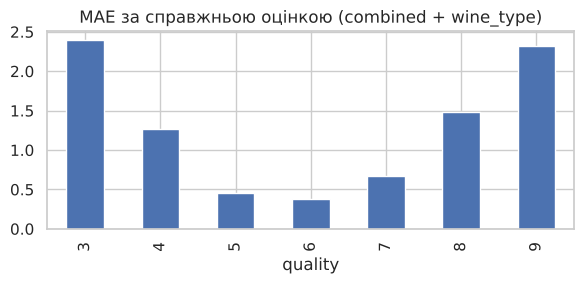

In [19]:
# MAE за кожною справжньою оцінкою (CV, спільна модель з wine_type)
err = pd.DataFrame({"quality": y, "abs_err": np.abs(y - oof["combined + wine_type"]),
                    "type": df["wine_type"].map({0: "red", 1: "white"})})
by_q = err.groupby("quality")["abs_err"].agg(["mean", "count"]).round(3)
display(by_q)
by_q["mean"].plot(kind="bar", figsize=(6, 3), title="MAE за справжньою оцінкою (combined + wine_type)")
plt.tight_layout(); plt.show()

## 8. Висновки та обмеження

**Дублікати:** видалено 240 рядків у red (15.0%) і 937 у white (19.1%); лишилось 1359 + 3961 = 5320.

**Результати 5-fold CV (RMSE, менше = краще; baseline на всьому наборі = 0.880):**

| Підмножина | Окремі моделі | Спільна + `wine_type` | Спільна без `wine_type` |
|---|---|---|---|
| Усі | 0.6867 | 0.6863 | 0.6861 |
| Red | 0.6545 | 0.6475 | 0.6465 |
| White | 0.6971 | 0.6988 | 0.6988 |

* Усі три RF-підходи істотно кращі за baseline (R² ≈ 0.39 проти 0). На red-підмножині baseline-RMSE = 0.841, на white = 0.893.
* Різниця між окремими й спільною моделлю **в межах шуму**: розкид RMSE по фолдах — ±0.034–0.039 для red і ±0.005 для white, а різниця між сценаріями ≤ 0.007. Тобто за цими даними не можна стверджувати, що окремі моделі кращі за спільну (або навпаки).
* **Видалення `wine_type` майже нічого не змінює:** ΔRMSE від −0.001 до 0.000 (≈ 0%). Permutation importance самої `wine_type` ≈ 0.0004 — модель практично її не використовує: тип вина вже «зашитий» в інших хімічних показниках (загальний SO₂, летка кислотність, хлориди тощо).
* Червоні вина прогнозуються трохи точніше за RMSE, але в них є лише 1359 рядків, тому оцінка нестабільніша (більший розкид по фолдах).
* Hold-out (один поділ 80/20) дає схожу картину, але на ньому окрема red-модель виглядає краще за спільну (0.625 проти 0.637) — це ілюструє, що один поділ шумний; довіряти слід CV.

**Permutation importance:** у всіх моделях лідирує `alcohol`; далі `volatile acidity`. Відмінності між типами: для red важливі `sulphates` (0.078), для white — `free sulfur dioxide` (0.051). У спільній моделі `sulphates` вагомо нижчі (0.025) — частково вона «усереднює» ці відмінності.

**Аналіз помилок:** MAE мінімальна для класів 5–6 (≈ 0.38–0.46) і різко зростає для рідкісних 3, 4, 8, 9 (1.3–2.4): модель тяжіє до середніх оцінок (регресія до середнього), крайні оцінки майже не вгадує.

**Обмеження:**
* Гіперпараметри RF не налаштовувались.
* `quality` — суб'єктивна оцінка дегустаторів, класи сильно незбалансовані; macro-precision/recall нестабільні.
* Дублікати видалялись за повним збігом рядка; в UCI немає ідентифікатора вина, тож частина «дублікатів» могла бути різними винами з однаковими показниками.
* Permutation importance на корельованих ознаках (density / alcohol / residual sugar) розподіляє вагу між ними й може занижувати кожну окремо.
* Висновки стосуються цього датасету й RF з базовими параметрами.

**Відтворюваність:** `SEED = 42`, версії бібліотек друкуються в першій комірці; запуск — `jupyter nbconvert --to notebook --execute wine_rf_comparison.ipynb`. (~2.5 хв на 2 ядрах.)